# DS5110 — Homework 2
## Tidy Data, Join Cardinality, and Data Visualization

This notebook explores tidy data principles, reshapes quarterly
revenue data, examines join cardinality, and constructs an
analysis-ready dataset.

In [1]:
import pandas as pd

revenue = pd.read_csv("company_quarterly_revenue_raw.csv")
orders = pd.read_csv("orders-1.csv")
shipments = pd.read_csv("shipments.csv")

## Step 0: Raw Data Inspection

In [2]:
print(revenue.shape)
revenue.head()

(5, 13)


,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


In [3]:
# Examine the orders dataset
print("Orders shape:", orders.shape)
display(orders.head())

# Examine the shipments dataset
print("Shipments shape:", shipments.shape)
display(shipments.head())

Orders shape: (20, 5)


,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


Shipments shape: (35, 2)


,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1


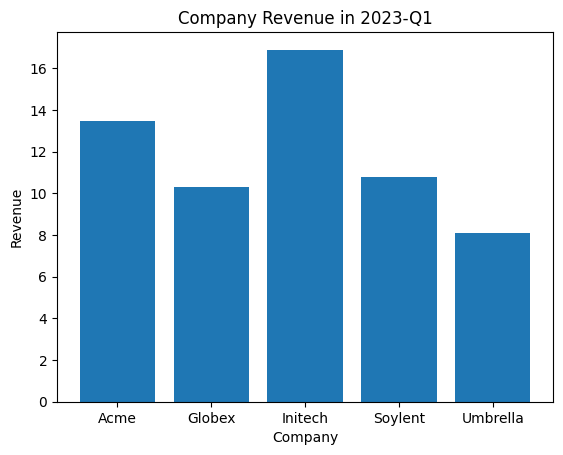

(20, 5)


In [4]:
import matplotlib.pyplot as plt

plt.bar(revenue["company"], revenue["2023-Q1"])

plt.xlabel("Company")
plt.ylabel("Revenue")
plt.title("Company Revenue in 2023-Q1")

plt.show()

print(orders.shape)

## Step 1: Reshaping Revenue Data

In [5]:
revenue_tidy = pd.melt(
    revenue,
    id_vars=["company"],
    var_name="quarter",
    value_name="revenue"
)

print(revenue_tidy.shape)
display(revenue_tidy.head())
revenue_tidy.tail()

(60, 3)


,company,quarter,revenue
0,Acme,2023-Q1,13.5
1,Globex,2023-Q1,10.3
2,Initech,2023-Q1,16.9
3,Soylent,2023-Q1,10.8
4,Umbrella,2023-Q1,8.1


,company,quarter,revenue
55,Acme,2025-Q4,20.3
56,Globex,2025-Q4,14.0
57,Initech,2025-Q4,22.3
58,Soylent,2025-Q4,23.6
59,Umbrella,2025-Q4,14.3


## Step 2: Join Cardinality

In [6]:
print("Orders unique:", orders["order_id"].is_unique)

print("Shipments unique:", shipments["order_id"].is_unique)


Orders unique: True
Shipments unique: False


In [7]:
joined = pd.merge(
    orders,
    shipments,
    on="order_id",
    how="left",
    validate="one_to_many"
)

print("Orders rows:", len(orders))
print("Shipments rows:", len(shipments))
print("Joined rows:", len(joined))

display(joined.head(10))

Orders rows: 20
Shipments rows: 35
Joined rows: 35


,order_id,customer_id,amount,company,quarter,tracking
0,O1000,C106,26,Umbrella,2024-Q4,O1000-1
1,O1001,C105,48,Umbrella,2023-Q3,O1001-1
2,O1001,C105,48,Umbrella,2023-Q3,O1001-2
3,O1002,C103,155,Globex,2025-Q2,O1002-1
4,O1003,C100,38,Acme,2023-Q4,O1003-1
5,O1003,C100,38,Acme,2023-Q4,O1003-2
6,O1004,C103,136,Globex,2023-Q3,O1004-1
7,O1004,C103,136,Globex,2023-Q3,O1004-2
8,O1004,C103,136,Globex,2023-Q3,O1004-3
9,O1005,C107,144,Soylent,2023-Q4,O1005-1


## Step 3: Mean Amount Comparison

In [8]:
# A. Mean amount per customer from joined table
mean_joined = joined.groupby("customer_id")["amount"].mean()

print("Mean from joined table:")
display(mean_joined)

# B. Mean amount per customer from original orders
mean_orders = orders.groupby("customer_id")["amount"].mean()

print("Mean from orders table:")
display(mean_orders)

Mean from joined table:


customer_id
C100     38.000
C101     62.000
C102    105.000
C103    112.375
C104     33.000
C105     67.625
C106     62.250
C107    106.000
Name: amount, dtype: float64

Mean from orders table:


customer_id
C100     38.00
C101     62.00
C102    105.00
C103    111.60
C104     33.00
C105     67.25
C106     59.50
C107     96.50
Name: amount, dtype: float64

In [9]:
comparison = pd.DataFrame({
    "mean_joined": mean_joined,
    "mean_orders": mean_orders
})

comparison["difference"] = (
    comparison["mean_joined"] - comparison["mean_orders"]
)

display(comparison)

,mean_joined,mean_orders,difference
customer_id,,,
C100,38.000,38.00,0.000
C101,62.000,62.00,0.000
C102,105.000,105.00,0.000
C103,112.375,111.60,0.775
C104,33.000,33.00,0.000
C105,67.625,67.25,0.375
C106,62.250,59.50,2.750
C107,106.000,96.50,9.500


## Step 4: Analysis-Ready Table

In [10]:
analysis_table = pd.merge(
    orders,
    revenue_tidy,
    on=["company", "quarter"],
    how="left",
    validate="many_to_one"
)

print("Orders shape:", orders.shape)
print("Analysis table shape:", analysis_table.shape)

display(analysis_table.head())


Orders shape: (20, 5)
Analysis table shape: (20, 6)


,order_id,customer_id,amount,company,quarter,revenue
0,O1000,C106,26,Umbrella,2024-Q4,10.4
1,O1001,C105,48,Umbrella,2023-Q3,7.7
2,O1002,C103,155,Globex,2025-Q2,13.8
3,O1003,C100,38,Acme,2023-Q4,16.8
4,O1004,C103,136,Globex,2023-Q3,9.4


In [11]:
shipment_summary = (
    shipments.groupby("order_id")["tracking"]
    .count()
    .reset_index(name="shipment_count")
)

display(shipment_summary.head())

,order_id,shipment_count
0,O1000,1
1,O1001,2
2,O1002,1
3,O1003,2
4,O1004,3


In [12]:
final_table = pd.merge(
    analysis_table,
    shipment_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

In [13]:
print(final_table.shape)
display(final_table.head(10))

(20, 7)


,order_id,customer_id,amount,company,quarter,revenue,shipment_count
0,O1000,C106,26,Umbrella,2024-Q4,10.4,1
1,O1001,C105,48,Umbrella,2023-Q3,7.7,2
2,O1002,C103,155,Globex,2025-Q2,13.8,1
3,O1003,C100,38,Acme,2023-Q4,16.8,2
4,O1004,C103,136,Globex,2023-Q3,9.4,3
5,O1005,C107,144,Soylent,2023-Q4,15.4,3
6,O1006,C101,62,Acme,2024-Q3,18.4,1
7,O1007,C103,64,Globex,2025-Q2,13.8,1
8,O1008,C106,48,Umbrella,2025-Q2,11.8,3
9,O1009,C105,122,Umbrella,2023-Q2,6.1,2


In [14]:
print(final_table.isna().sum())

order_id          0
customer_id       0
amount            0
company           0
quarter           0
revenue           0
shipment_count    0
dtype: int64


## Step 5: Visualization Comparison

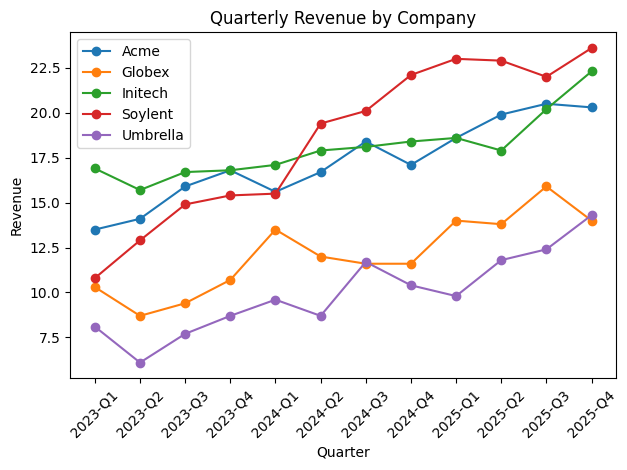

In [15]:
import matplotlib.pyplot as plt

for company, group in revenue_tidy.groupby("company"):
    plt.plot(
        group["quarter"],
        group["revenue"],
        marker="o",
        label=company
    )

plt.xlabel("Quarter")
plt.ylabel("Revenue")
plt.title("Quarterly Revenue by Company")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [16]:
print("Revenue tidy:", revenue_tidy.shape)
print("Final table:", final_table.shape)

print("\nMissing values:")
print(final_table.isna().sum())

print("\nDuplicate order IDs:")
print(final_table["order_id"].duplicated().sum())

print("Same order IDs:",
      set(final_table["order_id"]) == set(orders["order_id"]))


Revenue tidy: (60, 3)
Final table: (20, 7)

Missing values:
order_id          0
customer_id       0
amount            0
company           0
quarter           0
revenue           0
shipment_count    0
dtype: int64

Duplicate order IDs:
0
Same order IDs: True


In [17]:
print("Same order IDs:",
      set(final_table["order_id"]) == set(orders["order_id"]))

print("Unique order IDs:",
      final_table["order_id"].is_unique)

Same order IDs: True
Unique order IDs: True


## Conclusion

The original revenue table was transformed from wide format into
tidy format using pd.melt(). The relationship between orders and
shipments was identified as one-to-many.

The join increased the number of rows from 20 to 35 because some
orders had multiple shipments. This affected the calculation of
mean order amounts for several customers.

To avoid row multiplication, I summarized shipment information
before constructing the final analysis table.

The final table contains 20 rows and 7 columns, with no missing
values or duplicate order IDs. All original order IDs were preserved.